## 1. Imports & configuration

In [8]:
import sys
print(sys.executable)
%pip install rasterio
%pip install "numpy<2" "rasterio==1.3.10" geopandas

c:\anaconda3\python.exe
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [9]:
import os
import re
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch
import geopandas as gpd
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask

print(f'matplotlib {matplotlib.__version__}  |  rasterio {rasterio.__version__}')

matplotlib 3.9.2  |  rasterio 1.3.10


## 2. User configuration — edit this cell

| Setting | Description |
|---|---|
| `IMAGE_DIR` | Folder that contains your 11 GeoTIFFs |
| `FILE_GLOB` | Glob pattern to match your files |
| `DATE_PATTERN` | Regex that captures the acquisition date from the filename |
| `DATE_FORMAT` | `strptime` format string matching the captured date string |
| `VV_BAND / VH_BAND` | 1-based band indices inside each file |
| `THUMBNAIL_SIZE` | Pixel size for resampling thumbnails |
| `VV_RANGE / VH_RANGE` | Display colour stretch in dB |

In [10]:
# ── path to your images ───────────────────────────────────────────────────────
IMAGE_DIR   = Path('C:\\backscatter_output_iw2\\backscatter')
FILE_GLOB   = '*.tif'             # adjust if needed, e.g. '*.tiff' or 'S1*_gamma0*.tif'

# ── coherence products ───────────────────────────────────────────────────────
COHERENCE_DIR   = Path(r'C:\coherence_output\coherence')
COHERENCE_GLOB  = '*.tif'
COHERENCE_BAND  = 1
COH_RANGE       = (0.0, 1.0)       # coherence is usually in the 0–1 range

# ── field selection from parquet ──────────────────────────────────────────────
FIELDS_PARQUET  = Path(r'U:\\Kursbiblioteket\\GE9010\\student_files\\Berezkova Kristine (krbe2133)\\Sebastian_output\\field_geometries_samples_crop_residues_crop3_fieldlevel_dalarna.parquet')
FIELD_ID_COLUMN = 'field_id'      # change to your ID column name
FIELD_ID_VALUE  = '26748'       # change to the field you want

# ── date parsing ─────────────────────────────────────────────────────────────
DATE_PATTERN = r'(\d{8})T'        # captures 8-digit date before 'T'
DATE_FORMAT  = '%Y%m%d'           # format of the captured group

# ── band indices (1-based) ────────────────────────────────────────────────────
VV_BAND = 1
VH_BAND = 2

# ── display settings ─────────────────────────────────────────────────────────
THUMBNAIL_SIZE = 256              # thumbnail resampling resolution (px)
VV_RANGE       = (-25, 0)         # dB colour stretch for VV
VH_RANGE       = (-35, -5)        # dB colour stretch for VH
COLORMAP       = 'gray'           # matplotlib colormap

# ── figure layout ─────────────────────────────────────────────────────────────
FIG_WIDTH_PER_IMAGE = 2.8         # inches per scene on the x-axis
ROW_HEIGHT          = 3.0         # inches per band row

# ── load and select one field ─────────────────────────────────────────────────
fields_gdf = gpd.read_parquet(FIELDS_PARQUET)
if FIELD_ID_COLUMN not in fields_gdf.columns:
    raise ValueError(
        f"Column '{FIELD_ID_COLUMN}' not found. Available: {list(fields_gdf.columns)}"
    )

field_matches = fields_gdf[fields_gdf[FIELD_ID_COLUMN].astype(str) == str(FIELD_ID_VALUE)]
if field_matches.empty:
    raise ValueError(
        f"No field found for {FIELD_ID_COLUMN}={FIELD_ID_VALUE}. "
        f"Example IDs: {fields_gdf[FIELD_ID_COLUMN].astype(str).head(5).tolist()}"
    )

selected_field_gdf = field_matches.iloc[[0]].copy()
print(f"Selected field: {FIELD_ID_COLUMN}={FIELD_ID_VALUE}")

Selected field: field_id=26748


## 3. Discover & sort images

In [11]:
def parse_date_from_filename(filename: str) -> datetime | None:
    """Extract acquisition datetime from a Sentinel-1 filename."""
    match = re.search(DATE_PATTERN, filename)
    if match:
        return datetime.strptime(match.group(1), DATE_FORMAT)
    return None


# Collect all matching files and their dates
scenes = []
for fp in sorted(IMAGE_DIR.glob(FILE_GLOB)):
    date = parse_date_from_filename(fp.name)
    if date is None:
        print(f'  ⚠  Could not parse date from "{fp.name}" — skipping')
        continue
    scenes.append({'path': fp, 'date': date})

# Sort chronologically
scenes.sort(key=lambda s: s['date'])

print(f'Found {len(scenes)} scenes:')
for i, s in enumerate(scenes):
    print(f'  [{i+1:02d}]  {s["date"].strftime("%Y-%m-%d")}  {s["path"].name}')

Found 11 scenes:
  [01]  2024-06-02  Gamma0_dB_S1A_IW_SLC__1SDV_20240602T052322_20240602T052349_054140_06956E_A0EA_20260419_134237.tif
  [02]  2024-06-14  Gamma0_dB_S1A_IW_SLC__1SDV_20240614T052322_20240614T052349_054315_069B7A_6007_20260419_141939.tif
  [03]  2024-06-26  Gamma0_dB_S1A_IW_SLC__1SDV_20240626T052321_20240626T052348_054490_06A192_EC42_20260419_145536.tif
  [04]  2024-07-08  Gamma0_dB_S1A_IW_SLC__1SDV_20240708T052321_20240708T052348_054665_06A7A7_874E_20260419_154003.tif
  [05]  2024-07-20  Gamma0_dB_S1A_IW_SLC__1SDV_20240720T052320_20240720T052347_054840_06ADB3_95F4_20260419_162812.tif
  [06]  2024-08-01  Gamma0_dB_S1A_IW_SLC__1SDV_20240801T052320_20240801T052347_055015_06B3CE_DB73_20260419_171509.tif
  [07]  2024-08-13  Gamma0_dB_S1A_IW_SLC__1SDV_20240813T052320_20240813T052347_055190_06BA07_D0A3_20260419_180055.tif
  [08]  2024-08-25  Gamma0_dB_S1A_IW_SLC__1SDV_20240825T052320_20240825T052347_055365_06C085_0C8A_20260419_184338.tif
  [09]  2024-09-06  Gamma0_dB_S1A_IW_SL

## 4. Load thumbnails

In [12]:
def load_thumbnail(path: Path, band: int, size: int) -> np.ndarray:
    """Read one band in the selected field ROI and mask to the exact field polygon."""
    with rasterio.open(path) as src:
        field_in_raster_crs = selected_field_gdf.to_crs(src.crs)
        geom = field_in_raster_crs.geometry.iloc[0]
        minx, miny, maxx, maxy = geom.bounds

        # Read only field ROI (bounding box window)
        roi_window = rasterio.windows.from_bounds(
            minx, miny, maxx, maxy, transform=src.transform
        )
        roi_window = roi_window.round_offsets().round_lengths()

        # Clip ROI window to raster extent
        full_window = rasterio.windows.Window(0, 0, src.width, src.height)
        roi_window = roi_window.intersection(full_window)

        if roi_window.width <= 0 or roi_window.height <= 0:
            return np.full((size, size), np.nan, dtype=np.float32)

        data = src.read(
            band,
            window=roi_window,
            out_shape=(size, size),
            resampling=Resampling.average,
            masked=True,
        )

        # Transform corresponding to the ROI thumbnail grid
        roi_transform = src.window_transform(roi_window)
        scale_x = roi_window.width / size
        scale_y = roi_window.height / size
        thumb_transform = roi_transform * roi_transform.scale(scale_x, scale_y)

        field_geom = [geom.__geo_interface__]
        inside_field = geometry_mask(
            field_geom,
            out_shape=(size, size),
            transform=thumb_transform,
            invert=True,
        )

    arr = data.astype(np.float32)
    arr[data.mask] = np.nan
    arr[~inside_field] = np.nan
    return arr


def parse_coherence_dates(filename: str):
    """Extract master/slave acquisition dates from a coherence filename."""
    match = re.search(r'Coh_.*?_(\d{8})_.*?_(\d{8})_', filename)
    if match:
        return (
            datetime.strptime(match.group(1), DATE_FORMAT),
            datetime.strptime(match.group(2), DATE_FORMAT),
        )
    return None


print('Loading thumbnails (ROI = selected field) …')
for s in scenes:
    s['vv'] = load_thumbnail(s['path'], VV_BAND, THUMBNAIL_SIZE)
    s['vh'] = load_thumbnail(s['path'], VH_BAND, THUMBNAIL_SIZE)

    vv_min = np.nanmin(s['vv']) if np.any(np.isfinite(s['vv'])) else np.nan
    vv_max = np.nanmax(s['vv']) if np.any(np.isfinite(s['vv'])) else np.nan
    vh_min = np.nanmin(s['vh']) if np.any(np.isfinite(s['vh'])) else np.nan
    vh_max = np.nanmax(s['vh']) if np.any(np.isfinite(s['vh'])) else np.nan

    print(f'  ✓  {s["date"].strftime("%Y-%m-%d")}  '
          f'VV [{vv_min:.1f}, {vv_max:.1f}] dB  '
          f'VH [{vh_min:.1f}, {vh_max:.1f}] dB')

coherence_scenes = []
for fp in sorted(COHERENCE_DIR.glob(COHERENCE_GLOB)):
    dates = parse_coherence_dates(fp.name)
    if dates is None:
        print(f'  ⚠  Could not parse dates from "{fp.name}" — skipping')
        continue
    d1, d2 = dates
    coherence_scenes.append({
        'path': fp,
        'start_date': d1,
        'end_date': d2,
        'label': f'{d1.strftime("%d %b %Y")} → {d2.strftime("%d %b %Y")}'
    })

coherence_scenes.sort(key=lambda s: s['start_date'])

print(f'Found {len(coherence_scenes)} coherence scenes:')
for i, s in enumerate(coherence_scenes):
    print(f'  [{i+1:02d}]  {s["label"]}  {s["path"].name}')

print('Loading coherence thumbnails (ROI = selected field) …')
for s in coherence_scenes:
    s['coh'] = load_thumbnail(s['path'], COHERENCE_BAND, THUMBNAIL_SIZE)
    coh_min = np.nanmin(s['coh']) if np.any(np.isfinite(s['coh'])) else np.nan
    coh_max = np.nanmax(s['coh']) if np.any(np.isfinite(s['coh'])) else np.nan
    print(f'  ✓  {s["label"]}  coh [{coh_min:.2f}, {coh_max:.2f}]')
print('Done.')

Loading thumbnails (ROI = selected field) …
  ✓  2024-06-02  VV [-35.6, -12.3] dB  VH [-19.8, -5.2] dB
  ✓  2024-06-14  VV [-26.1, -11.3] dB  VH [-20.9, -5.3] dB
  ✓  2024-06-26  VV [-28.3, -12.8] dB  VH [-22.8, -6.6] dB
  ✓  2024-07-08  VV [-23.6, -11.4] dB  VH [-19.4, -7.6] dB
  ✓  2024-07-20  VV [-29.5, -9.8] dB  VH [-22.9, -6.5] dB
  ✓  2024-08-01  VV [-28.0, -12.7] dB  VH [-24.5, -6.3] dB
  ✓  2024-08-13  VV [-30.0, -11.3] dB  VH [-20.9, -7.8] dB
  ✓  2024-08-25  VV [-27.9, -10.8] dB  VH [-21.8, -3.2] dB
  ✓  2024-09-06  VV [-39.9, -13.1] dB  VH [-21.8, -7.9] dB
  ✓  2024-09-18  VV [-28.8, -13.5] dB  VH [-26.4, -6.4] dB
  ✓  2024-09-30  VV [-37.8, -14.3] dB  VH [-19.8, -5.2] dB
Found 10 coherence scenes:
  [01]  02 Jun 2024 → 14 Jun 2024  Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW_SLC__1SDV_20240614_20260419_180346.tif
  [02]  14 Jun 2024 → 26 Jun 2024  Coh_S1A_IW_SLC__1SDV_20240614_S1A_IW_SLC__1SDV_20240626_20260420_094647.tif
  [03]  26 Jun 2024 → 08 Jul 2024  Coh_S1A_IW_SLC__1SDV_202

## 6. Optional — per-scene statistics table

In [13]:
import pandas as pd

rows = []
for s in scenes:
    rows.append({
        'Date':      s['date'].strftime('%Y-%m-%d'),
        'VV mean':   f"{np.nanmean(s['vv']):.2f}",
        'VV std':    f"{np.nanstd(s['vv']):.2f}",
        'VH mean':   f"{np.nanmean(s['vh']):.2f}",
        'VH std':    f"{np.nanstd(s['vh']):.2f}",
        'VV-VH mean': f"{np.nanmean(s['vv'] - s['vh']):.2f}",
    })

pd.DataFrame(rows).set_index('Date')

,VV mean,VV std,VH mean,VH std,VV-VH mean
Date,,,,,
2024-06-02,-19.89,2.94,-10.53,2.11,-9.36
2024-06-14,-16.61,2.19,-9.94,2.36,-6.67
2024-06-26,-18.17,2.05,-12.92,1.86,-5.25
2024-07-08,-16.67,2.05,-11.81,2.18,-4.86
2024-07-20,-16.62,2.44,-10.93,2.43,-5.69
2024-08-01,-17.46,1.92,-12.07,1.92,-5.39
2024-08-13,-17.97,2.13,-11.88,1.69,-6.09
2024-08-25,-15.65,2.37,-10.15,2.41,-5.49
2024-09-06,-18.19,2.51,-12.08,2.09,-6.11


## 7. Optional — interactive per-image colourbar figure

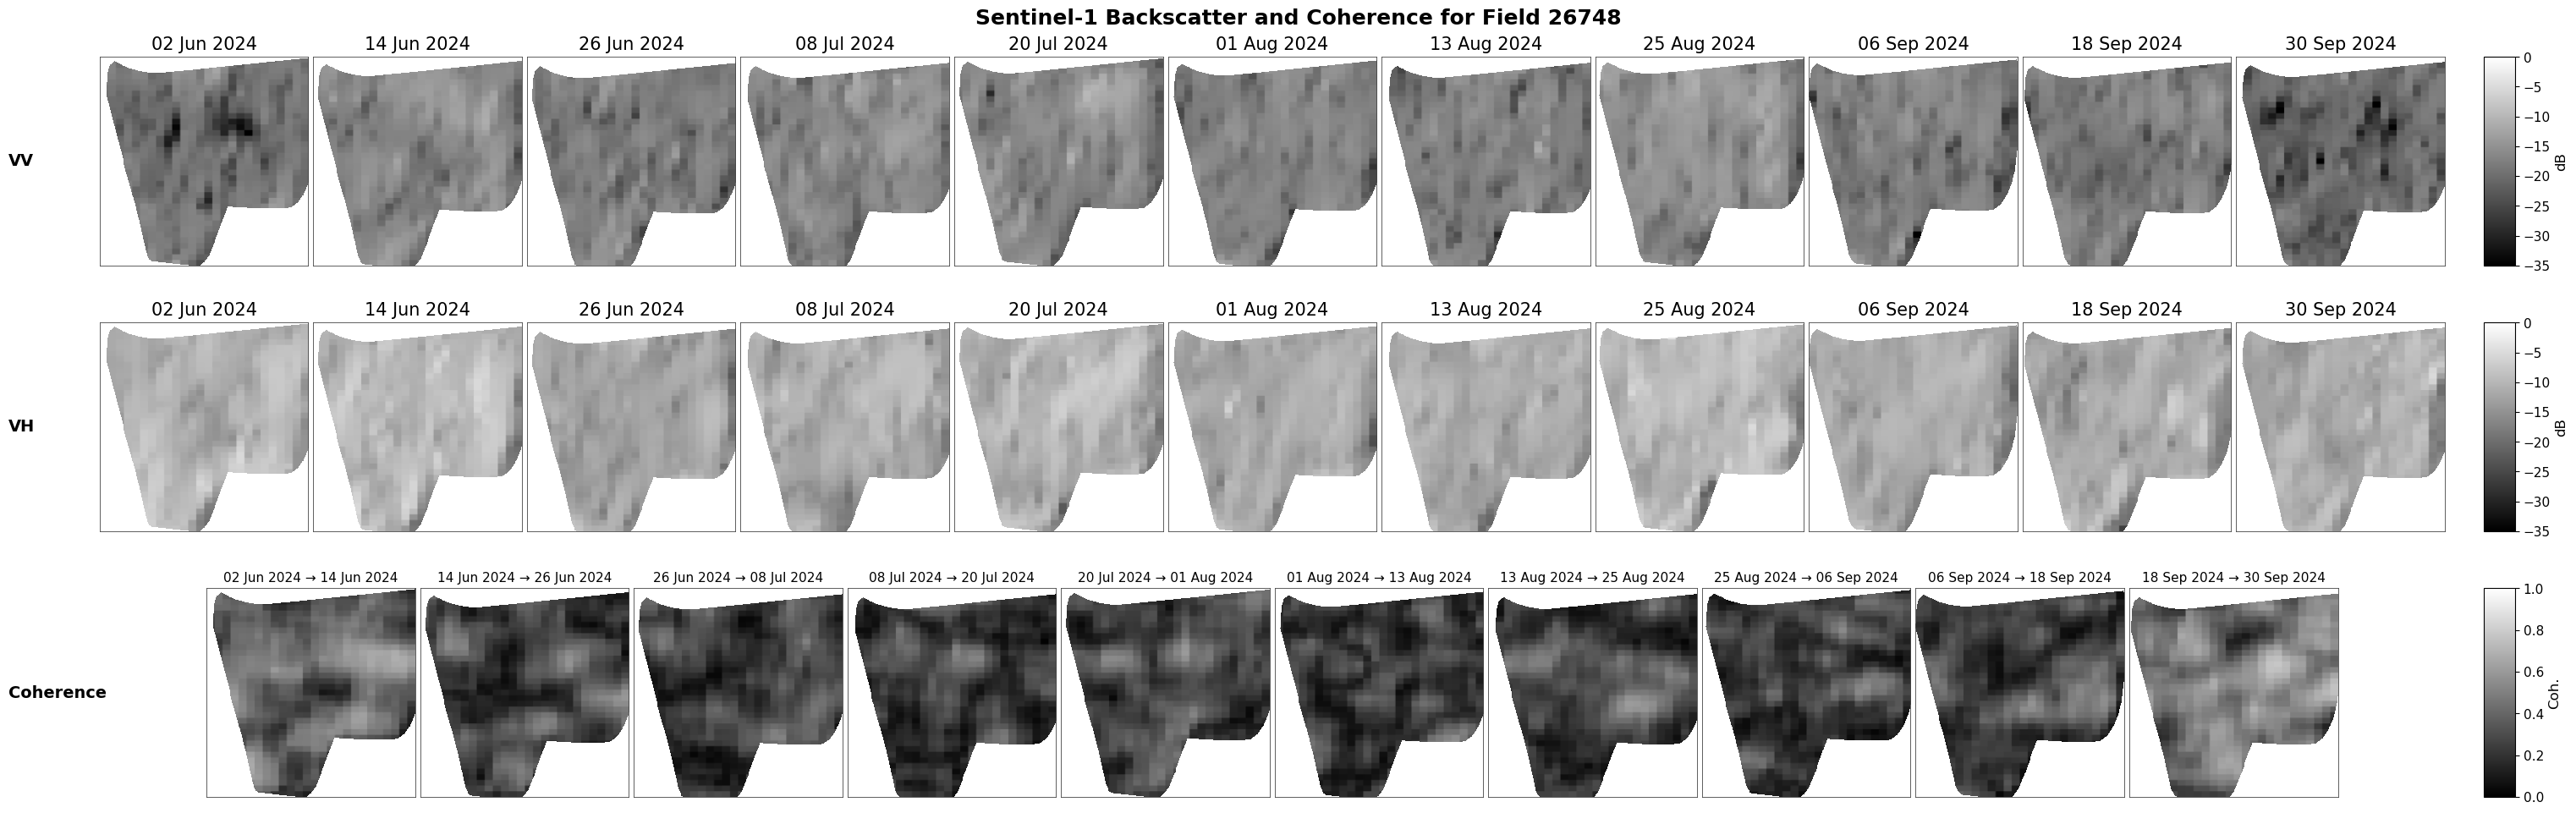

Figure saved → sentinel1_colourbar.png


In [14]:
# Final publication-style figure: VV, VH, and coherence rows
n_back = len(scenes)
n_coh = len(coherence_scenes)
assert n_back > 1, 'Need at least two backscatter scenes to place coherence between dates.'
assert n_coh > 0, 'No coherence scenes loaded — check COHERENCE_DIR and filename pattern.'

# Typography for article readability
TITLE_FONTSIZE = 18
DATE_FONTSIZE = 15
ROW_LABEL_FONTSIZE = 14
CBAR_LABEL_FONTSIZE = 12
CBAR_TICK_FONTSIZE = 11

# Shared color scales
SHARED_RANGE = (min(VV_RANGE[0], VH_RANGE[0]), max(VV_RANGE[1], VH_RANGE[1]))
COH_SHARED_RANGE = COH_RANGE

# Build a lookup so each coherence image sits between its matching backscatter dates
coh_lookup = {(s['start_date'], s['end_date']): s for s in coherence_scenes}

# Dedicated mappables for the shared colorbars
back_mappable = plt.cm.ScalarMappable(norm=plt.Normalize(*SHARED_RANGE), cmap=COLORMAP)
back_mappable.set_array([])
coh_mappable = plt.cm.ScalarMappable(norm=plt.Normalize(*COH_SHARED_RANGE), cmap=COLORMAP)
coh_mappable.set_array([])

fig2 = plt.figure(
    figsize=(FIG_WIDTH_PER_IMAGE * n_back, ROW_HEIGHT * 3 + 1.0),
    facecolor='white',
)

gs = fig2.add_gridspec(
    nrows=3,
    ncols=2 * n_back,
    height_ratios=[1, 1, 1],
    hspace=0.20,
    wspace=0.05,
    left=0.04, right=0.94, top=0.93, bottom=0.04,
)

# Row 1: VV backscatter
row1_axes = []
for i, s in enumerate(scenes):
    ax = fig2.add_subplot(gs[0, 2 * i:2 * i + 2])
    row1_axes.append(ax)
    ax.imshow(
        s['vv'],
        cmap=COLORMAP,
        vmin=SHARED_RANGE[0], vmax=SHARED_RANGE[1],
        origin='upper',
        interpolation='bilinear',
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')

    ax.set_title(s['date'].strftime('%d %b %Y'), color='black', fontsize=DATE_FONTSIZE)

    for spine in ax.spines.values():
        spine.set_edgecolor('#444444')
        spine.set_linewidth(0.6)

# Row 2: VH backscatter
row2_axes = []
for i, s in enumerate(scenes):
    ax = fig2.add_subplot(gs[1, 2 * i:2 * i + 2])
    row2_axes.append(ax)
    ax.imshow(
        s['vh'],
        cmap=COLORMAP,
        vmin=SHARED_RANGE[0], vmax=SHARED_RANGE[1],
        origin='upper',
        interpolation='bilinear',
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')

    ax.set_title(s['date'].strftime('%d %b %Y'), color='black', fontsize=DATE_FONTSIZE)

    for spine in ax.spines.values():
        spine.set_edgecolor('#444444')
        spine.set_linewidth(0.6)

# Row 3: coherence, centered below the VH row and under the matching backscatter pair
row3_axes = []
for i in range(n_back - 1):
    start = scenes[i]['date']
    end = scenes[i + 1]['date']
    s = coh_lookup.get((start, end))
    ax = fig2.add_subplot(gs[2, 2 * i + 1:2 * i + 3])
    row3_axes.append(ax)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor('white')

    if s is not None:
        ax.imshow(
            s['coh'],
            cmap=COLORMAP,
            vmin=COH_SHARED_RANGE[0], vmax=COH_SHARED_RANGE[1],
            origin='upper',
            interpolation='bilinear',
        )
        ax.set_title(s['label'], color='black', fontsize=11)
        for spine in ax.spines.values():
            spine.set_edgecolor('#444444')
            spine.set_linewidth(0.6)
    else:
        ax.text(0.5, 0.5, 'No coherence', ha='center', va='center', color='#777777', fontsize=10, transform=ax.transAxes)
        for spine in ax.spines.values():
            spine.set_edgecolor('#BBBBBB')
            spine.set_linewidth(0.4)

# Dedicated colorbars on the right side so the last backscatter image is not squeezed
row1_box = matplotlib.transforms.Bbox.union([ax.get_position() for ax in row1_axes])
row2_box = matplotlib.transforms.Bbox.union([ax.get_position() for ax in row2_axes])
row3_box = matplotlib.transforms.Bbox.union([ax.get_position() for ax in row3_axes])
fig2.text(
    0.005,
    row1_box.y0 + row1_box.height / 2,
    'VV',
    color='black',
    fontsize=ROW_LABEL_FONTSIZE,
    fontweight='bold',
    ha='left',
    va='center',
)
fig2.text(
    0.005,
    row2_box.y0 + row2_box.height / 2,
    'VH',
    color='black',
    fontsize=ROW_LABEL_FONTSIZE,
    fontweight='bold',
    ha='left',
    va='center',
)
fig2.text(
    0.005,
    row3_box.y0 + row3_box.height / 2,
    'Coherence',
    color='black',
    fontsize=ROW_LABEL_FONTSIZE,
    fontweight='bold',
    ha='left',
    va='center',
)
cbar_x = 0.955
cbar_w = 0.012
vv_cax = fig2.add_axes([cbar_x, row1_box.y0, cbar_w, row1_box.height])
cb = fig2.colorbar(back_mappable, cax=vv_cax)
cb.set_label('dB', color='black', fontsize=CBAR_LABEL_FONTSIZE)
cb.ax.yaxis.set_tick_params(color='black', labelsize=CBAR_TICK_FONTSIZE)
plt.setp(cb.ax.yaxis.get_ticklabels(), color='black')
vv_cax.set_facecolor('white')

coh_cax = fig2.add_axes([cbar_x, row3_box.y0, cbar_w, row3_box.height])
cb = fig2.colorbar(coh_mappable, cax=coh_cax)
cb.set_label('Coh.', color='black', fontsize=CBAR_LABEL_FONTSIZE)
cb.ax.yaxis.set_tick_params(color='black', labelsize=CBAR_TICK_FONTSIZE)
plt.setp(cb.ax.yaxis.get_ticklabels(), color='black')
coh_cax.set_facecolor('white')

vh_cax = fig2.add_axes([cbar_x, row2_box.y0, cbar_w, row2_box.height])
cb = fig2.colorbar(back_mappable, cax=vh_cax)
cb.set_label('dB', color='black', fontsize=CBAR_LABEL_FONTSIZE)
cb.ax.yaxis.set_tick_params(color='black', labelsize=CBAR_TICK_FONTSIZE)
plt.setp(cb.ax.yaxis.get_ticklabels(), color='black')
vh_cax.set_facecolor('white')

fig2.suptitle(
    f"Sentinel-1 Backscatter and Coherence for Field {FIELD_ID_VALUE}",
    color='black', fontsize=TITLE_FONTSIZE, fontweight='bold',
    y=0.98,
    x=0.5,
    ha='center',
)

fig2.subplots_adjust(left=0.04, right=0.93, top=0.90, bottom=0.04, hspace=0.20, wspace=0.05)
plt.savefig(
    'sentinel1_colourbar.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white',
    edgecolor='none'
)
plt.show()
print('Figure saved → sentinel1_colourbar.png')